# Airline financial resilience
## First reporting edition · annual baseline
**Prepared 25 October 2026 · source cutoff 24 October 2026**

Which airline groups have the balance-sheet and earnings capacity to absorb higher fuel expenses and tighter financing?

This report turns the public reporting database into a repeatable research workbook. It covers **24 provisional airline groups**, including easyJet, LATAM, Alaska and JetBlue. The global top-20 revenue ranking remains unverified. Years end between April 2025 and March 2026; these are not uniformly the latest available accounts.

**Read this as a screening report.** Book gearing, reported costs and a mechanical sensitivity highlight questions for further research. Current liquidity, debt covenants, hedges and refinancing conditions are not sufficiently populated to assign risk ratings.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "reporting.py").exists())
sys.path.insert(0, str(ROOT))
import pandas as pd
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from reporting import load_baseline, fuel_scenario
DATA, airlines = load_baseline()
OUT = ROOT / "reports"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titleweight": "bold", "savefig.facecolor": "white"})
BLUE, ORANGE = "#155e75", "#c76528"
assert len(airlines) == 24


## 1. Start with the evidence
The database preserves source links, page/table locators, currency, period and accounting notes. Missing values remain missing. Combined Emirates Group figures are retained in the baseline; the airline-only supplement is excluded from all cross-group charts here.

The checklist below tests nine headline inputs. A complete checklist does **not** imply complete credit diligence. Acquisition perimeters, non-airline businesses, perpetual equity and cash-flow classifications still affect comparability.

In [2]:
core = ["revenue", "assets", "equity", "cash", "fuel_cost", "staff_cost", "cfo", "capex", "debt_and_lease_carrying_amount"]
coverage = airlines[["entity", "period_end", "currency"]].copy()
coverage["Headline fields available"] = airlines[core].notna().sum(axis=1)
coverage["Missing headline inputs"] = airlines[core].apply(lambda r: ", ".join(r.index[r.isna()]) or "None", axis=1)
display(coverage.reset_index(drop=True))
complete = int((coverage["Headline fields available"] == len(core)).sum())
display(Markdown(f"**{complete} of 24 groups** have all nine headline inputs. The sample contains {len(DATA['observations'])} financial observations, including the separate Emirates airline supplement."))


,entity,period_end,currency,Headline fields available,Missing headline inputs
0,Delta Air Lines,2025-12-31,USD,9,None
1,Alaska Air Group,2025-12-31,USD,9,None
2,International Airlines Group,2025-12-31,EUR,9,None
3,Ryanair Holdings,2026-03-31,EUR,9,None
4,Turkish Airlines,2025-12-31,USD,9,None
5,Qatar Airways Group,2026-03-31,QAR,7,"fuel_cost, staff_cost"
6,Korean Air,2025-12-31,KRW,5,"fuel_cost, staff_cost, cfo, capex"
7,easyJet,2025-09-30,GBP,9,None
8,Qantas Group,2025-06-30,AUD,9,None
9,Air China,2025-12-31,CNY,9,None


**20 of 24 groups** have all nine headline inputs. The sample contains 416 financial observations, including the separate Emirates airline supplement.

## 2. Gearing: how much of the asset base is financed by debt and leases?
Debt and leases divided by assets is a first screening measure. It avoids the distortion of dividing by very small or negative equity, but it does not assess asset realisability, pledged collateral or debt service capacity.

The numerator combines identified debt and lease carrying amounts once. It is not every financing obligation: pensions, guarantees and separate fuel financing are outside this subtotal. US operating leases are included. Issuer cash balances are not netted because unrestricted availability is not yet verified. Sorting is descriptive, not a credit ranking.

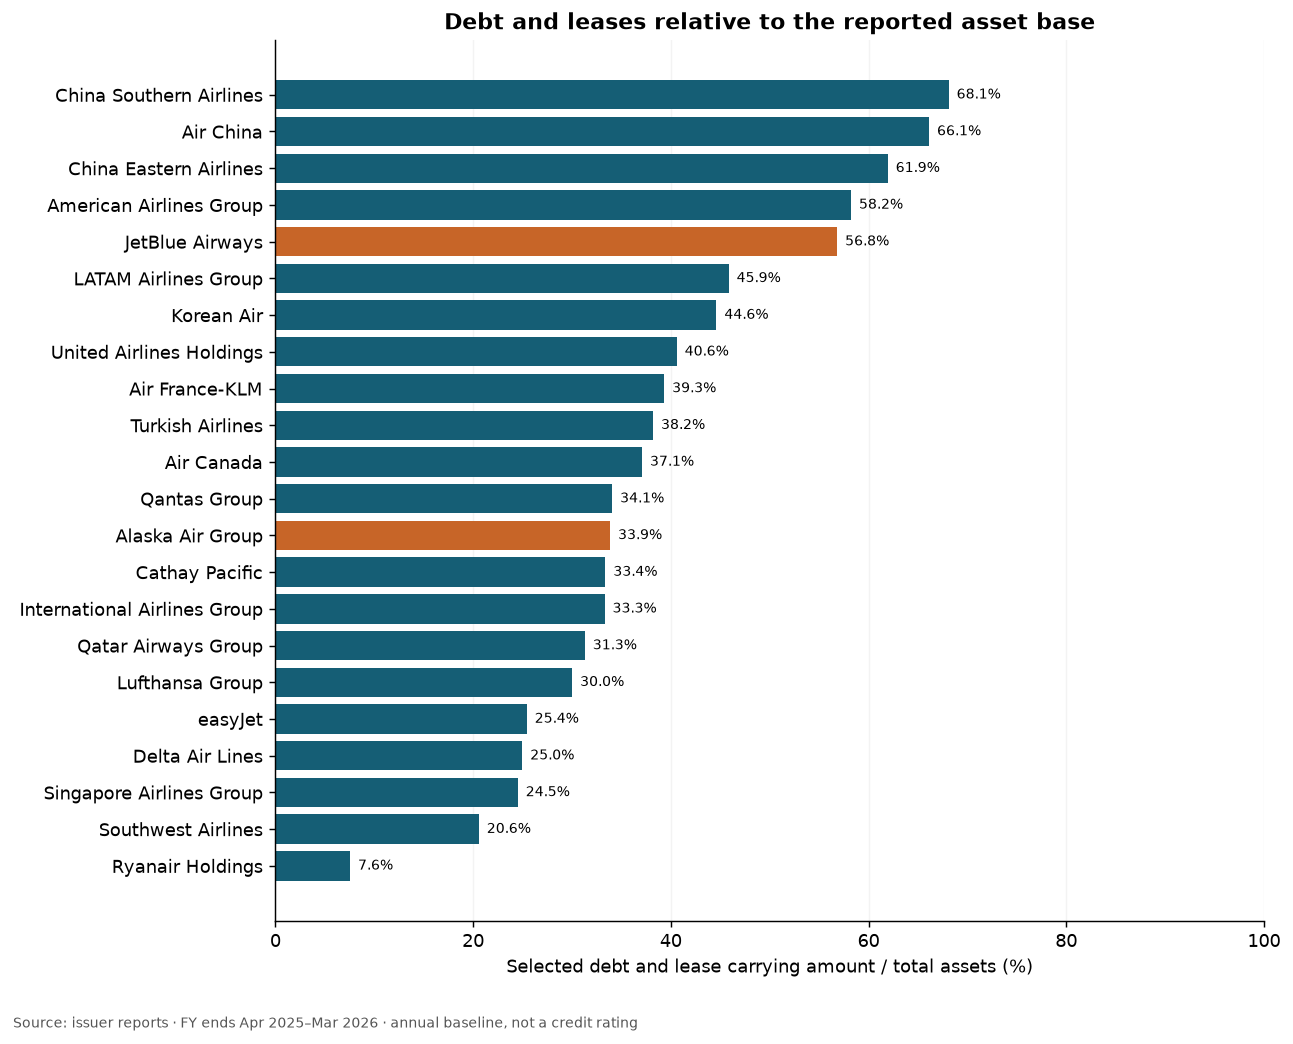

**Omitted for incomplete debt/lease perimeter:** ANA Holdings, Emirates Group.

,entity,period_end,Book debt/equity (x),equity_ratio_status
0,Delta Air Lines,2025-12-31,0.98,available
1,Alaska Air Group,2025-12-31,1.67,available
2,International Airlines Group,2025-12-31,1.88,available
3,Ryanair Holdings,2026-03-31,0.15,available
4,Turkish Airlines,2025-12-31,0.84,available
5,Qatar Airways Group,2026-03-31,0.74,available
6,Korean Air,2025-12-31,1.96,available
7,easyJet,2025-09-30,0.84,available
8,Qantas Group,2025-06-30,10.16,available
9,Air China,2025-12-31,5.79,available


In [3]:
gearing = airlines.dropna(subset=["debt_to_assets_pct"]).sort_values("debt_to_assets_pct")
fig, ax = plt.subplots(figsize=(10, 8))
colors = [ORANGE if i in ["jetblue", "alaska"] else BLUE for i in gearing.index]
ax.barh(gearing["entity"], gearing["debt_to_assets_pct"], color=colors)
ax.set(xlabel="Selected debt and lease carrying amount / total assets (%)",
       title="Debt and leases relative to the reported asset base")
ax.set_xlim(0, max(100, gearing["debt_to_assets_pct"].max()*1.15))
for y, v in enumerate(gearing["debt_to_assets_pct"]): ax.text(v+0.8, y, f"{v:.1f}%", va="center", fontsize=8)
ax.grid(axis="x", alpha=.15); ax.set_axisbelow(True)
fig.text(.01, .005, "Source: issuer reports · FY ends Apr 2025–Mar 2026 · annual baseline, not a credit rating", fontsize=8, color="#555")
fig.tight_layout(rect=[0, .035, 1, 1]); fig.savefig(OUT / "gearing.png", bbox_inches="tight"); plt.show()
missing = airlines.loc[airlines["debt_to_assets_pct"].isna(), "entity"].tolist()
display(Markdown("**Omitted for incomplete debt/lease perimeter:** " + ", ".join(missing) + "."))
display(airlines[["entity", "period_end", "debt_to_equity", "equity_ratio_status"]].rename(columns={"debt_to_equity":"Book debt/equity (x)"}).reset_index(drop=True).round(2))


American has negative book equity, so its debt/equity ratio is withheld. China Eastern and Air France-KLM include material perpetual securities within equity. Their unadjusted book gearing cannot be read as gearing against ordinary shareholders' equity. ANA's available parent-equity and issuer-debt disclosures are not substituted for total consolidated inputs.

## 3. Cost structure: exposure before hedges and pricing responses
Fuel and employee costs are shown as percentages of reported revenue, avoiding a comparison of unconverted currency amounts. Separate employee incentives are added where explicitly disclosed. These are two cost components, not a full operating-cost breakdown.

Revenue definitions, group activities, SAF charges and hedge accounting vary. Delta includes refinery activity; some issuers include other operating income in revenue. The chart identifies questions for the detailed notes, not efficiency winners.

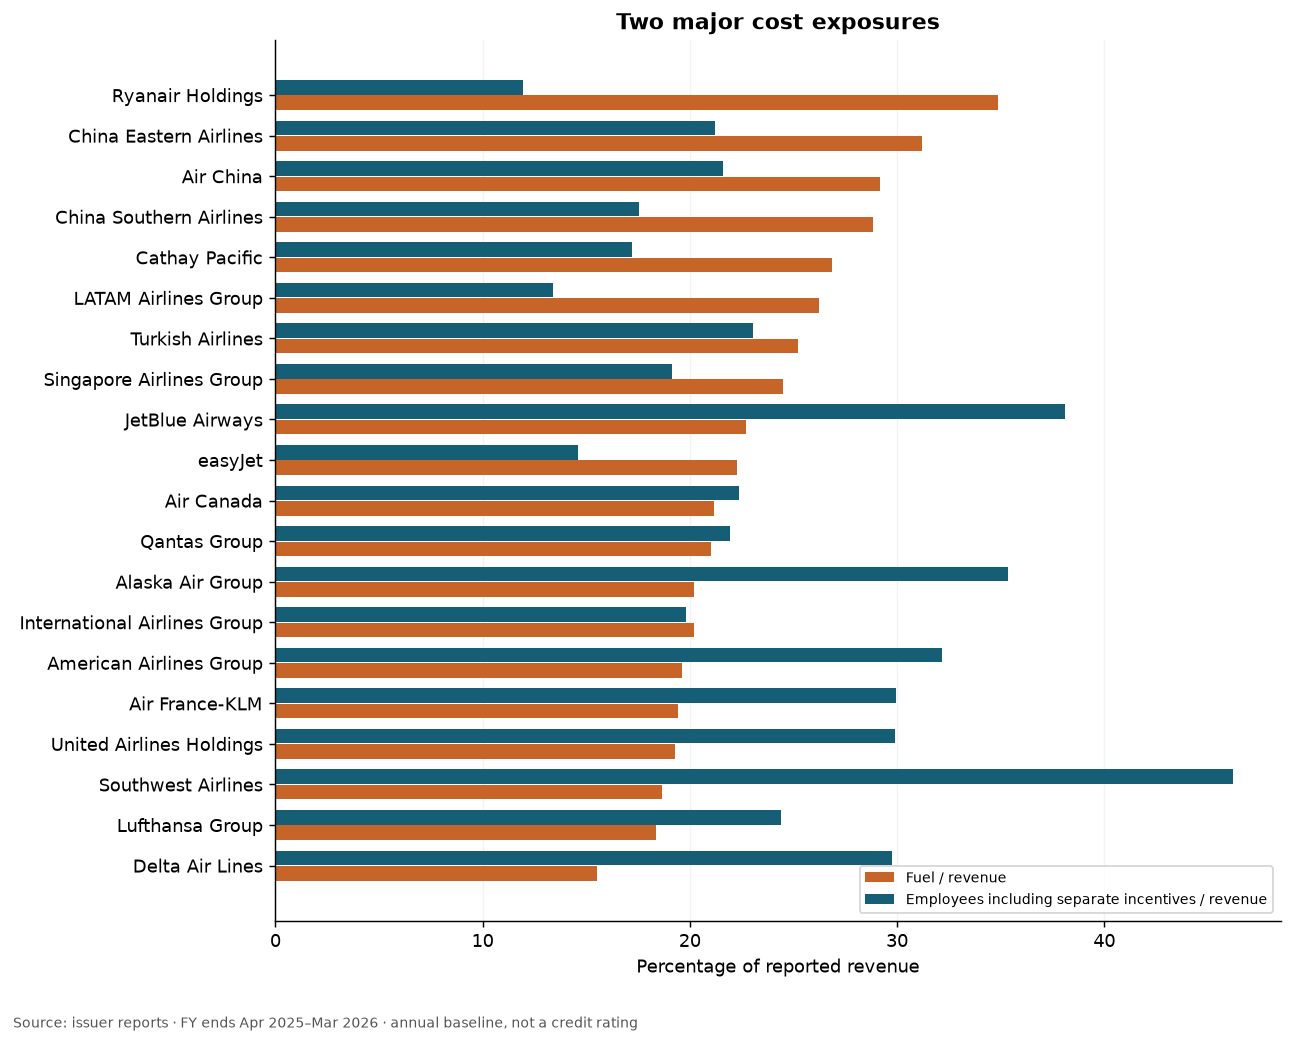

**Omitted for missing cost data:** Qatar Airways Group, Korean Air, ANA Holdings, Emirates Group.

In [4]:
costs = airlines.dropna(subset=["fuel_to_revenue_pct", "staff_to_revenue_pct"]).sort_values("fuel_to_revenue_pct")
fig, ax = plt.subplots(figsize=(10, 8))
y = range(len(costs))
ax.barh([i-.19 for i in y], costs["fuel_to_revenue_pct"], height=.36, label="Fuel / revenue", color=ORANGE)
ax.barh([i+.19 for i in y], costs["staff_to_revenue_pct"], height=.36, label="Employees including separate incentives / revenue", color=BLUE)
ax.set_yticks(list(y), costs["entity"])
ax.set(xlabel="Percentage of reported revenue", title="Two major cost exposures")
ax.legend(loc="lower right", fontsize=8); ax.grid(axis="x", alpha=.15); ax.set_axisbelow(True)
fig.text(.01, .005, "Source: issuer reports · FY ends Apr 2025–Mar 2026 · annual baseline, not a credit rating", fontsize=8, color="#555")
fig.tight_layout(rect=[0, .035, 1, 1]); fig.savefig(OUT / "cost_structure.png", bbox_inches="tight"); plt.show()
display(Markdown("**Omitted for missing cost data:** " + ", ".join(airlines.loc[~airlines.index.isin(costs.index), "entity"]) + "."))


## 4. Alaska and JetBlue: a focused comparison
Both use US GAAP and report in US dollars, making this a useful initial pair. Alaska's 2025 results include Hawaiian; differences in route networks and integration costs still matter. All monetary figures below are **USD millions**, for the year ended 31 December 2025.

CFO less capex is a simple subtraction, not a harmonised free-cash-flow measure. It precedes financing movements and may include different interest and aircraft-deposit classifications.

In [5]:
pair = airlines.loc[["alaska", "jetblue"]]
labels = {"revenue":"Revenue", "operating_profit":"Operating profit / (loss)", "operating_margin_pct":"Operating margin (%)",
          "debt_and_lease_carrying_amount":"Debt and leases", "equity":"Book equity", "debt_to_equity":"Debt / equity (x)",
          "cash":"Cash", "fuel_cost":"Fuel expense", "employee_cost_including_separate_incentives":"Employee costs incl. incentives",
          "cfo":"Operating cash flow", "capex":"Cash capital expenditure", "cfo_less_capex":"CFO less capex"}
comparison = pair.set_index("entity")[list(labels)].T.rename(index=labels)
display(comparison.round(2))
a, j = pair.loc["alaska"], pair.loc["jetblue"]
display(Markdown(f"**First finding:** JetBlue has debt and leases of **${j.debt_and_lease_carrying_amount:,.0f}m**, or **{j.debt_to_equity:.2f}×** book equity, versus Alaska's **{a.debt_to_equity:.2f}×**. JetBlue also reports an operating loss of **${-j.operating_profit:,.0f}m** and negative operating cash flow of **${-j.cfo:,.0f}m**. Together these warrant closer refinancing and liquidity review; they do not establish a probability of default."))


entity,Alaska Air Group,JetBlue Airways
Revenue,14239.00,9062.00
Operating profit / (loss),303.00,-368.00
Operating margin (%),2.13,-4.06
Debt and leases,6893.00,9416.00
Book equity,4118.00,2120.00
Debt / equity (x),1.67,4.44
Cash,627.00,1946.00
Fuel expense,2879.00,2057.00
Employee costs incl. incentives,5031.00,3453.00
Operating cash flow,1249.00,-94.00


**First finding:** JetBlue has debt and leases of **$9,416m**, or **4.44×** book equity, versus Alaska's **1.67×**. JetBlue also reports an operating loss of **$368m** and negative operating cash flow of **$94m**. Together these warrant closer refinancing and liquidity review; they do not establish a probability of default.

## 5. A transparent fuel-expense sensitivity
The parameter below increases the **reported annual fuel expense** by 10%. Revenue, flying, hedges, pass-through, other costs and tax are held unchanged. This is **not a 10% oil-price forecast**: fuel prices, inventories and hedge settlements need a separate model.

Use it to ask how much operating profit is exposed under a deliberately simple assumption. It is not a cash-runway or solvency scenario.

,baseline_operating_profit,extra_fuel_expense,scenario_operating_profit,scenario_operating_margin_pct
Alaska Air Group,303.0,287.9,15.1,0.11
JetBlue Airways,-368.0,205.7,-573.7,-6.33


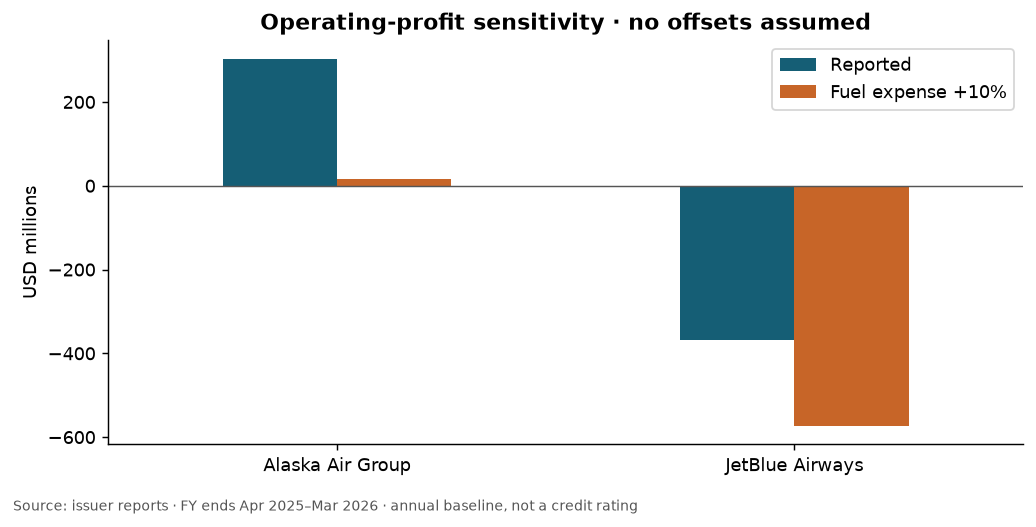

In [6]:
FUEL_EXPENSE_SHOCK = 0.10  # Change and rerun: 0.10 means +10% reported annual fuel expense.
scenarios = pd.DataFrame({row.entity: fuel_scenario(row, FUEL_EXPENSE_SHOCK) for _, row in pair.iterrows()}).T
scenarios.insert(0, "baseline_operating_profit", pair.set_index("entity")["operating_profit"])
display(scenarios.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
scenarios[["baseline_operating_profit", "scenario_operating_profit"]].rename(columns={"baseline_operating_profit":"Reported", "scenario_operating_profit":f"Fuel expense +{FUEL_EXPENSE_SHOCK:.0%}"}).plot.bar(ax=ax, color=[BLUE, ORANGE], rot=0)
ax.axhline(0, color="#555", linewidth=.8); ax.set(title="Operating-profit sensitivity · no offsets assumed", ylabel="USD millions", xlabel="")
fig.text(.01, .005, "Source: issuer reports · FY ends Apr 2025–Mar 2026 · annual baseline, not a credit rating", fontsize=8, color="#555")
fig.tight_layout(rect=[0, .035, 1, 1]); fig.savefig(OUT / "fuel_sensitivity.png", bbox_inches="tight"); plt.show()


## 6. Refinancing: the first maturity schedule
JetBlue's annual filing provides the first populated ladder. These are debt and finance-lease maturities **net of debt issuance costs**, excluding operating leases. The calendar-2026 bucket is $755m, while the balance sheet's current debt/finance-lease classification is $769m. Both issuer presentations are retained; they are not forced to reconcile.

This is a snapshot at December 2025, **not the remaining maturities as of October 2026**. Later repayments, financing and changes need an interim bridge.

In [7]:
maturities = pd.DataFrame(DATA["debt_maturities"])
display(maturities[["bucket", "value"]].rename(columns={"bucket":"Maturity period", "value":"JetBlue USD millions"}))
assert maturities["value"].sum() == 8498


,Maturity period,JetBlue USD millions
0,2026,755
1,2027,411
2,2028,516
3,2029,1768
4,2030,589
5,thereafter,4459


## 7. How this becomes a recurring public report
Each edition should lead with a short evidence-based finding, followed by the same four lenses: financing, cost exposure, cash generation and refinancing. A dated change log should distinguish new source data from model changes.

| Next reporting layer | Evidence required | Result |
|---|---|---|
| Current position | Latest interim balance sheets and matching prior periods | Current debt, liquidity and trailing earnings |
| Financing pressure | Debt notes, repayment schedules, covenants, facilities and pledged assets | Refinancing needs and funding headroom |
| Fuel vulnerability | Volumes, hedge coverage/strikes, currencies and price pass-through | Explicit oil/fuel scenarios |
| Risk assessment | Reconciled definitions plus downside cash bridges | Explained risk designations with uncertainty |

**Release discipline:** rebuild the database, run checks, execute this notebook from a clean kernel, inspect the charts, then publish the notebook and a code-free HTML reading copy. Keep annual baseline and interim evidence separate. Do not infer a risk category solely from a missing field or a single ratio.

## Source trail
The appendix below links every underlying observation used in the baseline. It includes source-specific definitions and notes. Detailed financial validation and remaining gaps are described in the repository's database guide.

In [8]:
evidence = pd.DataFrame(DATA["observations"])
evidence = evidence[evidence.report_id.isin(airlines.index)].copy()
evidence["airline"] = evidence.report_id.map(airlines.entity)
evidence["currency"] = evidence.report_id.map(airlines.currency)
evidence["period_end"] = evidence.report_id.map(airlines.period_end)
cols = ["airline", "period_end", "currency", "metric", "value", "source_url", "source_locator", "source_audit_status", "notes"]
display(evidence[cols].sort_values(["airline", "metric"]).style.format(precision=3, hyperlinks="html"))


,airline,period_end,currency,metric,value,source_url,source_locator,source_audit_status,notes
235,ANA Holdings,2026-03-31,JPY,assets,3955100.000,https://www.ana.co.jp/group/en/investors/data/pdf/presentations/26/2026_04_2e.pdf,PDF p23: consolidated financial position; JPYbn x1000,issuer results presentation,
240,ANA Holdings,2026-03-31,JPY,capex,262300.000,https://www.ana.co.jp/group/en/investors/data/pdf/presentations/26/2026_04_2e.pdf,PDF p25: cash flow; JPYbn x1000,issuer results presentation,Fixed-assets-only capital expenditure presented; cash-flow reconciliation pending.
238,ANA Holdings,2026-03-31,JPY,cash_and_investments,1256900.000,https://www.ana.co.jp/group/en/investors/data/pdf/presentations/26/2026_04_2e.pdf,PDF p23: consolidated financial position; JPYbn x1000,issuer results presentation,Cash/deposits plus marketable securities.
239,ANA Holdings,2026-03-31,JPY,cfo,443400.000,https://www.ana.co.jp/group/en/investors/data/pdf/presentations/26/2026_04_2e.pdf,PDF p25: cash flow; JPYbn x1000,issuer results presentation,
236,ANA Holdings,2026-03-31,JPY,equity_parent,1491900.000,https://www.ana.co.jp/group/en/investors/data/pdf/presentations/26/2026_04_2e.pdf,PDF p23: consolidated financial position; JPYbn x1000,issuer results presentation,
237,ANA Holdings,2026-03-31,JPY,issuer_debt,1171700.000,https://www.ana.co.jp/group/en/investors/data/pdf/presentations/26/2026_04_2e.pdf,PDF p23: consolidated financial position; JPYbn x1000,issuer results presentation,Issuer interest-bearing debt; lease reconciliation pending.
234,ANA Holdings,2026-03-31,JPY,net_profit_parent,169000.000,https://www.ana.co.jp/group/en/investors/data/pdf/presentations/26/2026_04_2e.pdf,PDF p22: consolidated full-year column; JPYbn x1000,issuer results presentation,
232,ANA Holdings,2026-03-31,JPY,operating_expenses,2321700.000,https://www.ana.co.jp/group/en/investors/data/pdf/presentations/26/2026_04_2e.pdf,PDF p22: consolidated full-year column; JPYbn x1000,issuer results presentation,
233,ANA Holdings,2026-03-31,JPY,operating_profit,217400.000,https://www.ana.co.jp/group/en/investors/data/pdf/presentations/26/2026_04_2e.pdf,PDF p22: consolidated full-year column; JPYbn x1000,issuer results presentation,
231,ANA Holdings,2026-03-31,JPY,revenue,2539200.000,https://www.ana.co.jp/group/en/investors/data/pdf/presentations/26/2026_04_2e.pdf,PDF p22: consolidated full-year column; JPYbn x1000,issuer results presentation,
